In [13]:
import pandas as pd 

df = pd.read_csv("covid19.csv")
df = df.fillna(0)
df['Date_reported'] = pd.to_datetime(df['Date_reported'])
df

,Date_reported,Country_code,Country,Continent,WHO_region,New_cases,Cumulative_cases,New_deaths,Cumulative_deaths
0,2020-01-05,AF,Afghanistan,Asia,EMRO,0.0,0,0.0,0
1,2020-01-12,AF,Afghanistan,Asia,EMRO,0.0,0,0.0,0
2,2020-01-19,AF,Afghanistan,Asia,EMRO,0.0,0,0.0,0
3,2020-01-26,AF,Afghanistan,Asia,EMRO,0.0,0,0.0,0
4,2020-02-02,AF,Afghanistan,Asia,EMRO,0.0,0,0.0,0
...,...,...,...,...,...,...,...,...,...
58555,2024-08-04,ZW,Zimbabwe,Africa,AFRO,1.0,266387,0.0,5740
58556,2024-08-11,ZW,Zimbabwe,Africa,AFRO,0.0,266387,0.0,5740
58557,2024-08-18,ZW,Zimbabwe,Africa,AFRO,0.0,266387,0.0,5740
58558,2024-08-25,ZW,Zimbabwe,Africa,AFRO,0.0,266387,0.0,5740


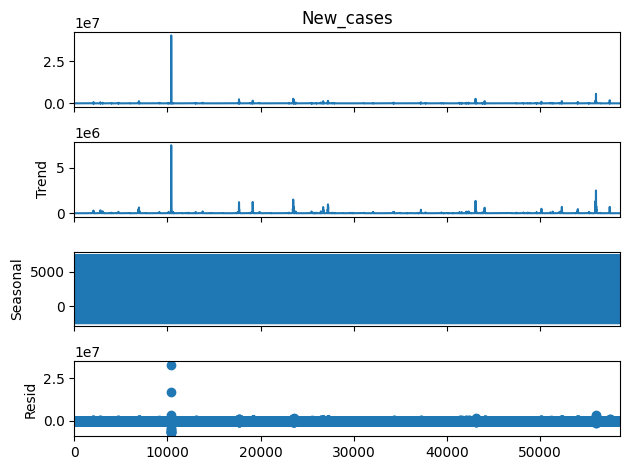

In [14]:
from statsmodels.tsa.seasonal import seasonal_decompose
import matplotlib.pyplot as plt

result = seasonal_decompose(df["New_cases"], model='additive', period=12)
result.plot()
plt.show()

MOVING AVERAGE

In [15]:
# Moving Average (7 hari)

df['Moving_Avg'] = df['New_deaths'].rolling(window=7).mean()
df[["New_deaths", "Moving_Avg"]].head(10)

,New_deaths,Moving_Avg
0,0.0,NaN
1,0.0,NaN
2,0.0,NaN
3,0.0,NaN
4,0.0,NaN
5,0.0,NaN
6,0.0,0.0
7,0.0,0.0
8,0.0,0.0
9,0.0,0.0


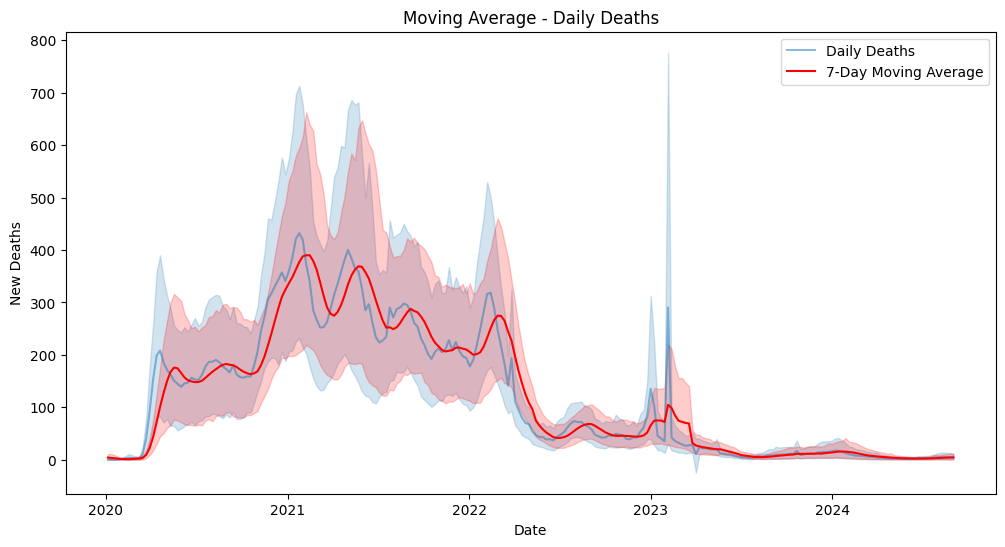

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 6))
sns.lineplot(x='Date_reported', y='New_deaths', data=df, label='Daily Deaths', alpha=0.5)
sns.lineplot(x='Date_reported', y='Moving_Avg', data=df, label='7-Day Moving Average', color='red')
plt.title('Moving Average - Daily Deaths')
plt.xlabel('Date')
plt.ylabel('New Deaths')
plt.legend()
plt.show()

EXPONENTIAL SMOOTHING

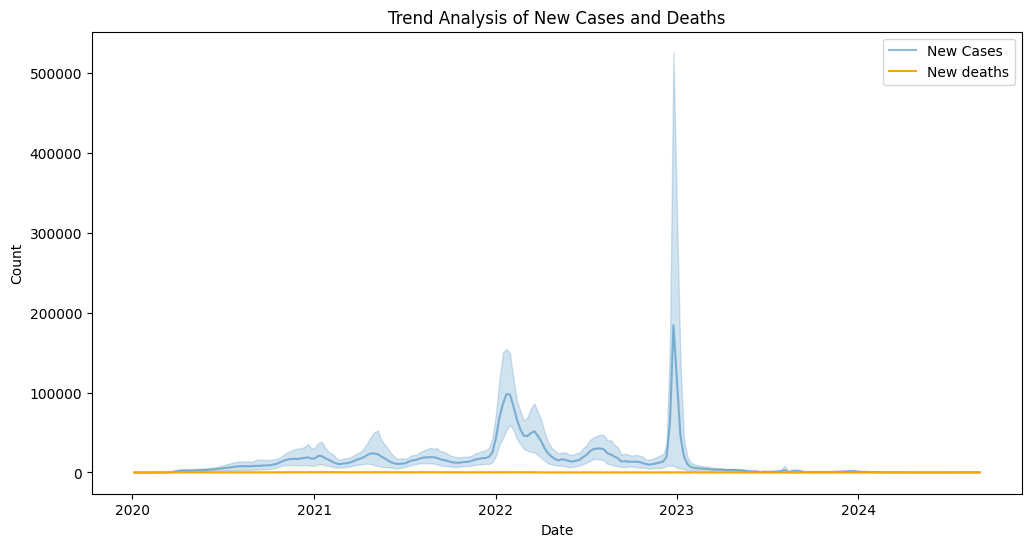

In [17]:
plt.figure(figsize=(12, 6))
sns.lineplot(x='Date_reported', y='New_cases', data=df, label='New Cases', alpha=0.5)
sns.lineplot(x='Date_reported', y='New_deaths', data=df, label='New deaths', color='orange')
plt.title('Trend Analysis of New Cases and Deaths')
plt.xlabel('Date')
plt.ylabel('Count')
plt.show()
